# JEM207 Sample Midterm
---
Boris Gerát - 13.11

**Practice version: 10 points (+ 2 bonus points), about 35 minutes.** Work without looking at solutions, set a timer, and score yourself at the end.

- Googling and Stack Overflow are allowed. Sharing code and using generative AI tools are not.
- If you get stuck, move on to the next task and come back later.
- Extract `sample_midterm_data.zip` next to this notebook (you should see a `data` folder).
- Your notebook must run from scratch: restart the kernel and run all cells before you finish.

In [1]:
%pip install pandas matplotlib

**TASK** Import the libraries. If you don't have them installed yet, use the code cell above to install them.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### PART 1: Prices (5 points)

The folder `data/prices/` has one CSV per coin (fictional cryptocurrencies, daily data). Use the `Close` column unless specified otherwise.

**TASK (1 pt)** Merge the three price files in `data/prices/` into one DataFrame. Add a `Ticker` column (taken from the file name), convert `Date` to datetime and set it as the index.

*Hint: read each file with `pd.read_csv`, then combine them with `pd.concat`.*

In [3]:
aurx = pd.read_csv("data/prices/AURX.csv")
aurx["Ticker"] = "AURX"

nova = pd.read_csv("data/prices/NOVA.csv")
nova["Ticker"] = "NOVA"

zeph = pd.read_csv("data/prices/ZEPH.csv")
zeph["Ticker"] = "ZEPH"

df = pd.concat([aurx, nova, zeph])
df["Date"] = pd.to_datetime(df["Date"])
df = df.set_index("Date").sort_index()
df.head()

,Open,High,Low,Close,Volume,Ticker
Date,,,,,,
2024-01-01,42164.26,43960.10,41962.16,43082.83,41339,AURX
2024-01-01,2298.57,2331.82,2291.62,2315.69,129266,NOVA
2024-01-01,95.05,95.69,93.04,94.11,2144777,ZEPH
2024-01-02,42948.12,42995.24,41423.30,41859.96,25884,AURX
2024-01-02,2309.76,2350.91,2277.67,2308.36,148306,NOVA


**TASK (1 pt)** For each coin, find the highest and the lowest price it recorded, and the date on which each occurred.

*Hint: think about which columns hold the extreme prices of a day.*

In [4]:
g = df.groupby("Ticker")
pd.DataFrame({
    "highest_high": g["High"].max(),
    "date_of_high": g["High"].idxmax(),
    "lowest_low": g["Low"].min(),
    "date_of_low": g["Low"].idxmin(),
})

,highest_high,date_of_high,lowest_low,date_of_low
Ticker,,,,
AURX,71741.11,2025-07-02,25047.40,2024-05-11
NOVA,10402.69,2025-12-21,2214.24,2024-01-06
ZEPH,255.68,2025-11-27,41.14,2024-11-26


**TASK (1 pt)** Calculate the daily percentage return of `Close` for each coin and report its mean, standard deviation, min and max.

Formula: $r_t = P_t / P_{t-1} - 1$, where $P_t$ is the price on day $t$.

*Hint: do it separately for each coin, not across the whole DataFrame.*

In [5]:
df["ret"] = df.groupby("Ticker")["Close"].pct_change()
df.groupby("Ticker")["ret"].agg(["mean", "std", "min", "max"])

,mean,std,min,max
Ticker,,,,
AURX,0.000683,0.030209,-0.124684,0.151234
NOVA,0.002631,0.038504,-0.112418,0.253877
ZEPH,0.002312,0.054386,-0.275275,0.298783


**TASK (1 pt)** Compute the average `Close` for each calendar month and each coin. Report the highest monthly average of each coin.

*Hint: check `resample`.*

In [6]:
monthly = df.groupby("Ticker")["Close"].resample("ME").mean()
monthly.groupby("Ticker").max()

Ticker
AURX    63652.226774
NOVA     9520.216129
ZEPH      210.104000
Name: Close, dtype: float64

**TASK (1 pt)** Plot the `Close` of AURX together with its 30-day rolling mean.

*Hint: check `rolling`.*

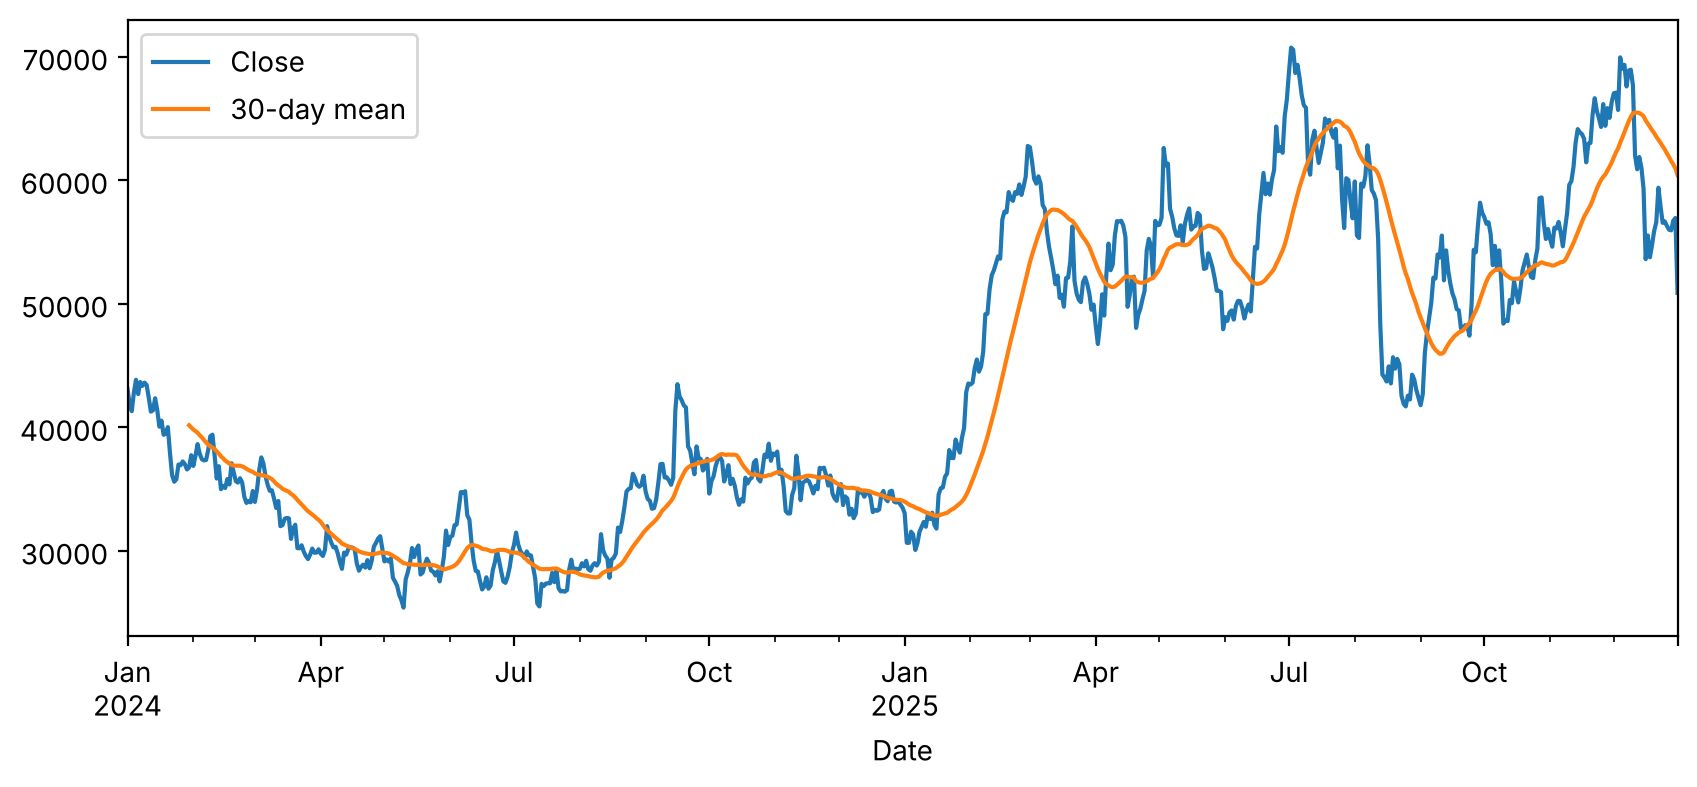

In [7]:
aurx_close = df.loc[df["Ticker"] == "AURX", "Close"]
aurx_close.plot(figsize=(10, 4), label="Close")
aurx_close.rolling(30).mean().plot(label="30-day mean")
plt.legend()
plt.show()

### PART 2: Coin metadata (3 points)

The file `data/coins/coins_no_subcategory.csv` describes a list of fictional coins.

**TASK (1 pt)** Load the file. How many missing values does each column have? Convert `listed` to datetime and remove the coins with a missing listing date.

*Hint: check `isna` and `dropna`.*

In [8]:
coins = pd.read_csv("data/coins/coins_no_subcategory.csv")
print(coins.isna().sum())
coins["listed"] = pd.to_datetime(coins["listed"])
coins = coins.dropna(subset=["listed"])
len(coins)

ticker      0
name        0
category    0
listed      6
founded     0
dtype: int64


34

**TASK (1 pt)** Which coin has the oldest and which the youngest listing date?

*Hint: `idxmin` and `idxmax` return the index label of the extreme value.*

In [9]:
oldest = coins.loc[coins["listed"].idxmin()]
youngest = coins.loc[coins["listed"].idxmax()]
print("Oldest:  ", oldest["ticker"], oldest["listed"].date())
print("Youngest:", youngest["ticker"], youngest["listed"].date())

Oldest:   DRAA 2013-02-11
Youngest: ELYO 2024-08-12


**TASK (1 pt)** Join this dataset with `data/coins/coins_subcategory.csv` using an appropriate key and report how many coins fall into each subcategory.

*Hint: both files share one column. Check `merge` and `value_counts`.*

In [10]:
sub = pd.read_csv("data/coins/coins_subcategory.csv")
merged = coins.merge(sub, on="ticker", how="left")
merged["subcategory"].value_counts()

subcategory
Algorithmic         4
Smart contracts     4
Metaverse           4
DEX                 3
Private payments    3
Derivatives         3
Bridge              2
Compute             2
Scaling             2
Payments            2
Crypto-backed       1
Lending             1
Oracle              1
Mixers              1
Play-to-earn        1
Name: count, dtype: int64

### PART 3: NumPy (2 points)

**TASK (1 pt)** Using NumPy, generate 500 random numbers from a normal distribution (mean 0, standard deviation 1) and 500 random numbers from a uniform distribution between 0 and 1. Print the mean and standard deviation of each sample.

*Hint: create a generator with `np.random.default_rng(42)` and check its `normal` and `uniform` methods.*

In [11]:
rng = np.random.default_rng(42)
normal_sample = rng.normal(loc=0, scale=1, size=500)
uniform_sample = rng.uniform(low=0, high=1, size=500)

print("Normal:  mean", normal_sample.mean().round(3), "std", normal_sample.std().round(3))
print("Uniform: mean", uniform_sample.mean().round(3), "std", uniform_sample.std().round(3))

Normal:  mean -0.013 std 0.959
Uniform: mean 0.498 std 0.295


**TASK (1 pt)** Plot a histogram of each sample, side by side in one figure, with a title for each.

*Hint: check `plt.subplots(1, 2)`.*

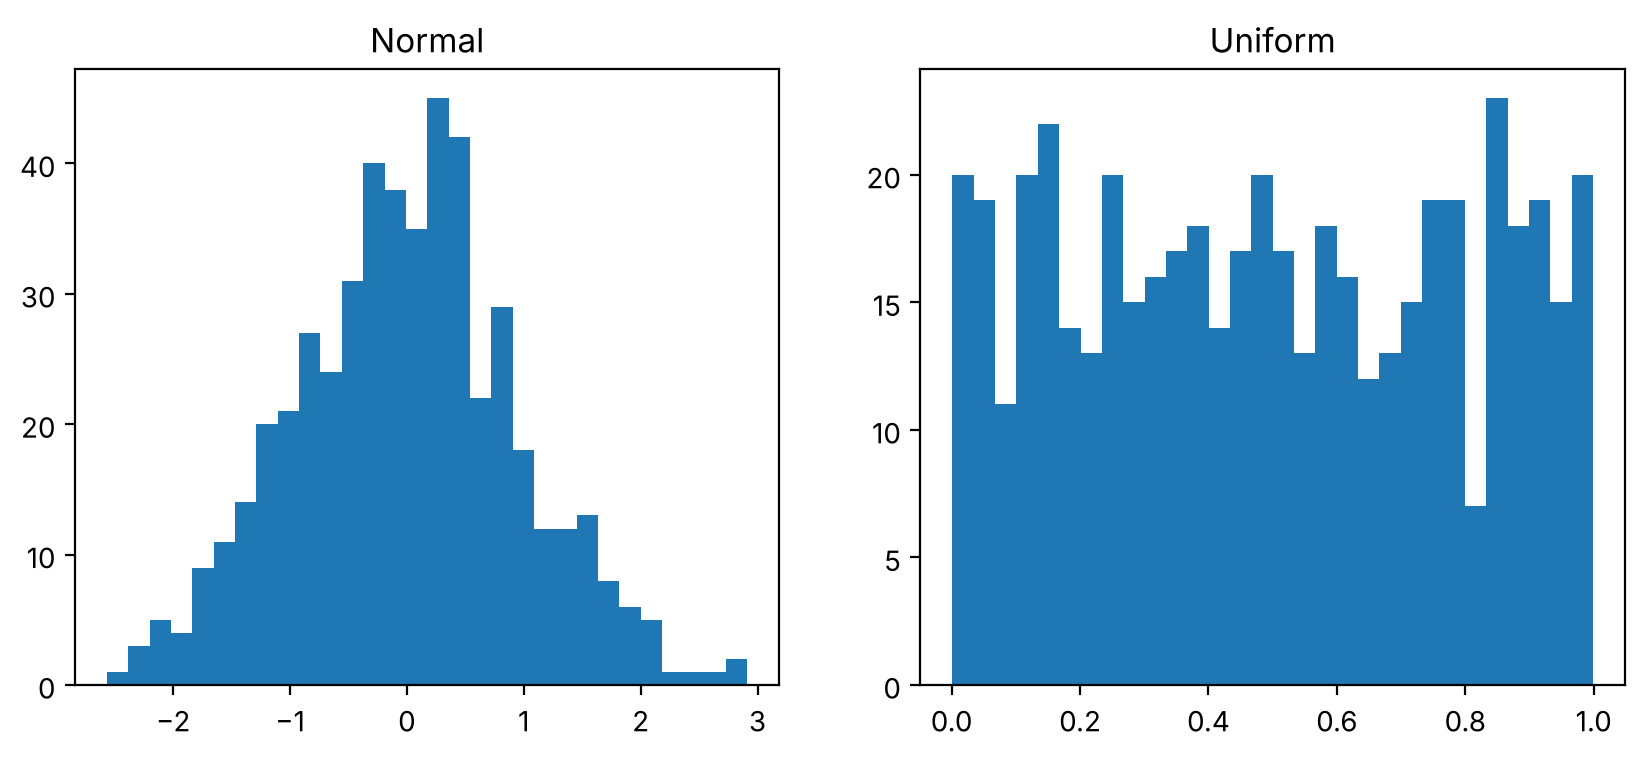

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(normal_sample, bins=30)
axes[0].set_title("Normal")
axes[1].hist(uniform_sample, bins=30)
axes[1].set_title("Uniform")
plt.show()

### BONUS: Fibonacci (2 bonus points)

Bonus points count on top of the 10 points. Each Fibonacci number is the sum of the two before it: 0, 1, 1, 2, 3, 5, 8, ...

**BONUS (1 pt)** Use a `for` loop to compute the first 15 Fibonacci numbers and store them in a list.

*Hint: start with the list `[0, 1]` and in each iteration append the sum of the last two numbers.*

In [13]:
fib = [0, 1]
for i in range(13):
    fib.append(fib[-1] + fib[-2])
fib

[0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377]

**BONUS (1 pt)** Using a `for` loop and an `if` condition, compute the sum of the even numbers in your Fibonacci list.

*Hint: `x % 2 == 0` checks whether `x` is even.*

In [14]:
even_sum = 0
for x in fib:
    if x % 2 == 0:
        even_sum += x
even_sum

188